## Домашнее задание 2

Пользоваться нейросетками не нужно. Нужно гуглить, можно читать документацию opencv и сайт stackoverflow.

Настройте себе работу с юпитер ноутбуком, чтобы было *удобно*, чтобы все нормально и предсказуемо запускалось, чтобы все в среде программирования было понятно.

В качестве результата работы в некоторых задачах потребуется записать короткое видео (буквально несколько мегабайт) и загрузить его вместе с .ipynb файлом.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

### Задача 1

Настройте фильтры в цветовом пространстве RGB на какой-нибудь объект дома. Это может быть чашка, шапка, клоунский нос (у кого имеется).

С помощью морфологических операций уберите из маски шум.

In [ ]:
def open_(mask, kernel):
    eroded = cv2.erode(mask, kernel)
    return cv2.dilate(eroded, kernel)


def close_(mask, kernel):
    dilated = cv2.dilate(mask, kernel)
    return cv2.erode(dilated, kernel)


def open_close(mask, kernel):
    return open_(close_(mask, kernel), kernel)


def close_open(mask, kernel):
    return close_(open_(mask, kernel), kernel)


def get_bgr_limits(window_name="mask"):
    b_low = cv2.getTrackbarPos("b_low", window_name)
    g_low = cv2.getTrackbarPos("g_low", window_name)
    r_low = cv2.getTrackbarPos("r_low", window_name)
    b_high = cv2.getTrackbarPos("b_high", window_name)
    g_high = cv2.getTrackbarPos("g_high", window_name)
    r_high = cv2.getTrackbarPos("r_high", window_name)
    return (b_low, g_low, r_low), (b_high, g_high, r_high)


def get_sq_kernel(window_name="mask"):
    k_size = cv2.getTrackbarPos("sq_k_size", window_name)
    k_size = k_size if k_size % 2 != 0 else k_size + 1
    return np.ones((k_size, k_size), np.uint8)


def get_circ_kernel(window_name="mask"):
    k_size = cv2.getTrackbarPos("circ_k_size", window_name)
    k_size = k_size if k_size % 2 != 0 else k_size + 1
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))


cv2.namedWindow("mask")
cv2.createTrackbar("b_low", "mask", 37, 255, lambda i: i)
cv2.createTrackbar("g_low", "mask", 15, 255, lambda i: i)
cv2.createTrackbar("r_low", "mask", 220, 255, lambda i: i)
cv2.createTrackbar("b_high", "mask", 200, 255, lambda i: i)
cv2.createTrackbar("g_high", "mask", 255, 255, lambda i: i)
cv2.createTrackbar("r_high", "mask", 255, 255, lambda i: i)
cv2.createTrackbar("sq_k_size", "mask", 11, 255, lambda i: i)
cv2.createTrackbar("circ_k_size", "mask", 45, 255, lambda i: i)

cam = cv2.VideoCapture(0)

while True:
    ret, frame = cam.read()
    if not ret:
        break

    lower_bgr, upper_bgr = get_bgr_limits()
    mask = cv2.inRange(frame, lower_bgr, upper_bgr)

    sq_k = get_sq_kernel()
    circ_k = get_circ_kernel()
    filtered_mask = close_open(open_close(mask, sq_k), circ_k)

    res = np.hstack((mask, filtered_mask))
    cv2.imshow("Result", res)

    if cv2.waitKey(30) & 0xFF == ord("q"):
        break

cam.release()
cv2.destroyAllWindows()

# Результат.

Слева до применения морфологии, справа после применения.

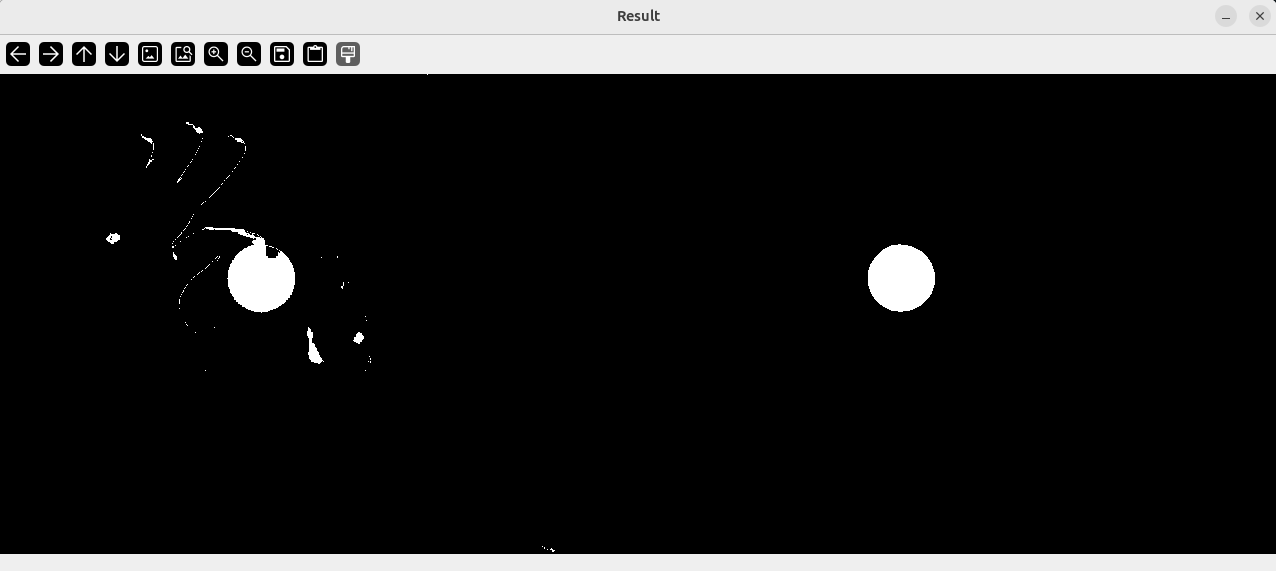

### Задача 2

Добавьте в кадр несколько шумовых объектов. Можно надеть пестрый свитер, раскидать что-нибудь на столе. В общем усложнить себе жизнь.

Отфильтруйте их по площади, используя анализ связных компонент.

In [ ]:
def get_bgr_limits(window_name="mask"):
    b_low = cv2.getTrackbarPos("b_low", window_name)
    g_low = cv2.getTrackbarPos("g_low", window_name)
    r_low = cv2.getTrackbarPos("r_low", window_name)
    b_high = cv2.getTrackbarPos("b_high", window_name)
    g_high = cv2.getTrackbarPos("g_high", window_name)
    r_high = cv2.getTrackbarPos("r_high", window_name)
    return (b_low, g_low, r_low), (b_high, g_high, r_high)


def get_sq_kernel(window_name="mask"):
    k_size = cv2.getTrackbarPos("sq_k_size", window_name)
    k_size = k_size if k_size % 2 != 0 else k_size + 1
    return np.ones((k_size, k_size), np.uint8)


def get_circ_kernel(window_name="mask"):
    k_size = cv2.getTrackbarPos("circ_k_size", window_name)
    k_size = k_size if k_size % 2 != 0 else k_size + 1
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))


cv2.namedWindow("mask")
cv2.createTrackbar("b_low", "mask", 37, 255, lambda i: i)
cv2.createTrackbar("g_low", "mask", 15, 255, lambda i: i)
cv2.createTrackbar("r_low", "mask", 200, 255, lambda i: i)
cv2.createTrackbar("b_high", "mask", 200, 255, lambda i: i)
cv2.createTrackbar("g_high", "mask", 255, 255, lambda i: i)
cv2.createTrackbar("r_high", "mask", 255, 255, lambda i: i)
cv2.createTrackbar("sq_k_size", "mask", 11, 255, lambda i: i)
cv2.createTrackbar("circ_k_size", "mask", 45, 255, lambda i: i)
cv2.createTrackbar("threshold_area", "mask", 7000, 50000, lambda i: i)

cam = cv2.VideoCapture(0)

while True:
    ret, frame = cam.read()
    if not ret:
        break

    lower_bgr, upper_bgr = get_bgr_limits()
    mask = cv2.inRange(frame, lower_bgr, upper_bgr)

    sq_k = get_sq_kernel()
    circ_k = get_circ_kernel()
    filtered_mask = close_open(open_close(mask, sq_k), circ_k)

    num_components, labels, stats, _ = cv2.connectedComponentsWithStats(filtered_mask)
    threshold_area = cv2.getTrackbarPos("threshold_area", "mask")

    area_mask = np.zeros_like(filtered_mask)
    for i in range(1, num_components):
        area = stats[i, cv2.CC_STAT_AREA]

        if area >= threshold_area:
            continue

        area_mask[labels == i] = 255

        x = stats[i, cv2.CC_STAT_LEFT]
        y = stats[i, cv2.CC_STAT_TOP]
        w = stats[i, cv2.CC_STAT_WIDTH]
        h = stats[i, cv2.CC_STAT_HEIGHT]

        cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(
            frame,
            f"Area: {area}",
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1,
        )

    mask_bgr = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    filtered_bgr = cv2.cvtColor(filtered_mask, cv2.COLOR_GRAY2BGR)
    area_bgr = cv2.cvtColor(area_mask, cv2.COLOR_GRAY2BGR)

    cv2.putText(
        frame,
        "1. Frame",
        (20, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
    )
    cv2.putText(
        mask_bgr,
        "2. Mask",
        (20, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
    )
    cv2.putText(
        filtered_bgr,
        "3. Filtered Mask",
        (20, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
    )
    cv2.putText(
        area_bgr,
        "4. Area Mask",
        (20, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
    )

    top = np.hstack((frame, mask_bgr))
    bottom = np.hstack((filtered_bgr, area_bgr))
    res = np.vstack((top, bottom))

    cv2.imshow("Result", res)

    if cv2.waitKey(30) & 0xFF == ord("q"):
        break

cam.release()
cv2.destroyAllWindows()

# Результат.

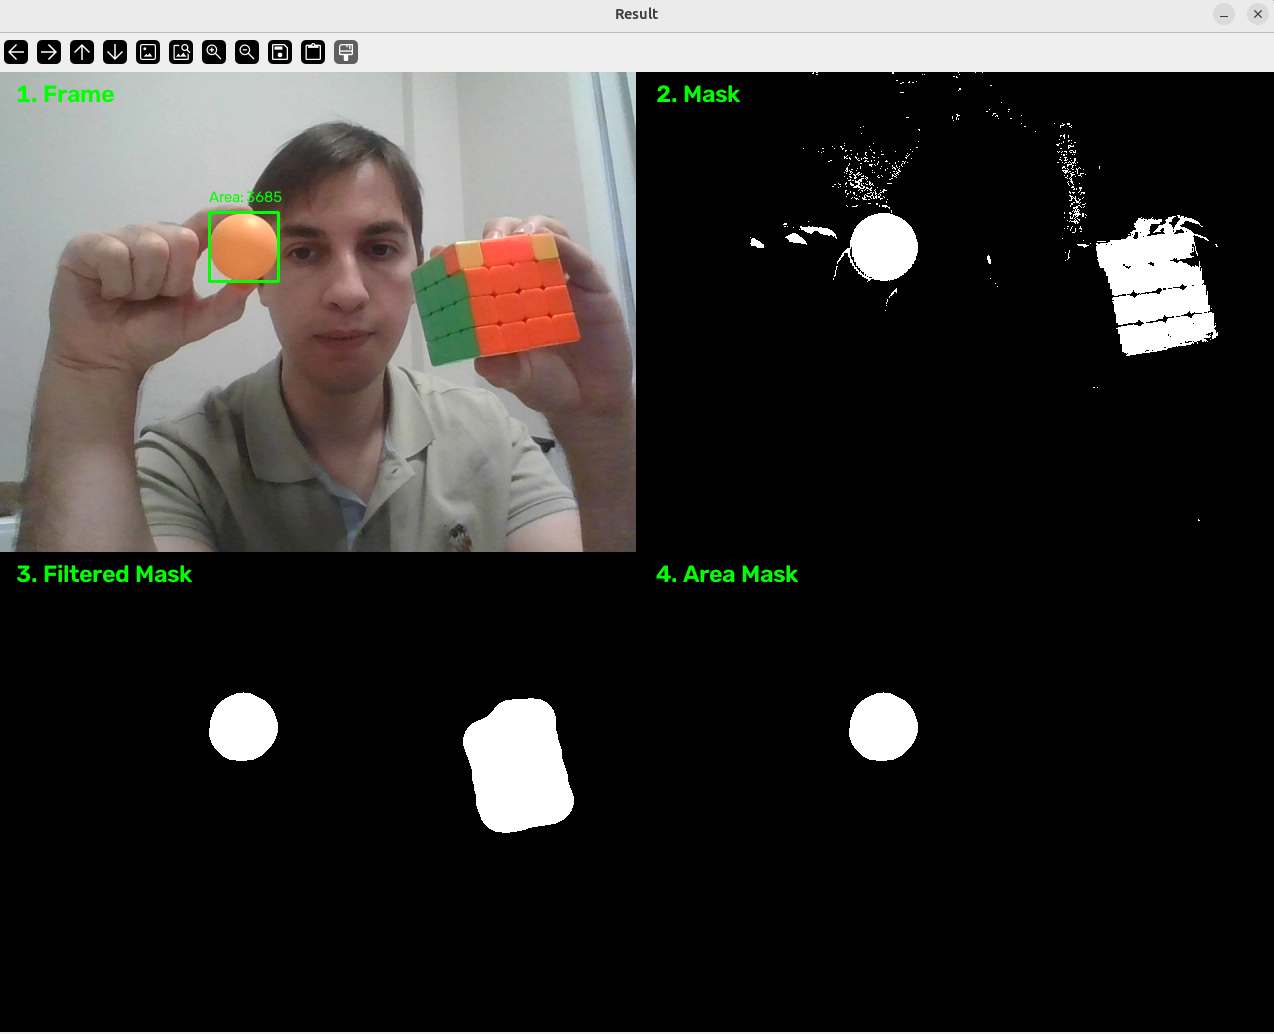

### Задача 3

Постройте распределения яркостей во всех трех каналах RGB. Покажите в камеру зеленый объект. Посмотрите, что получилось.

In [ ]:
cam = cv2.VideoCapture(0)
ret, frame = cam.read()
cam.release()

if ret:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].imshow(rgb)
    axes[0].axis('off')
    axes[0].set_title("Исходная фотография")

    colors = ['red', 'green', 'blue']
    for i, color in enumerate(colors):
        hist = cv2.calcHist([rgb], [i], None, [256], [0, 256])

        axes[1].plot(hist, color=color, label=color)

    plt.xlabel("Интенсивность")
    plt.ylabel("Количество пикселей")
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()

**Результаты:**

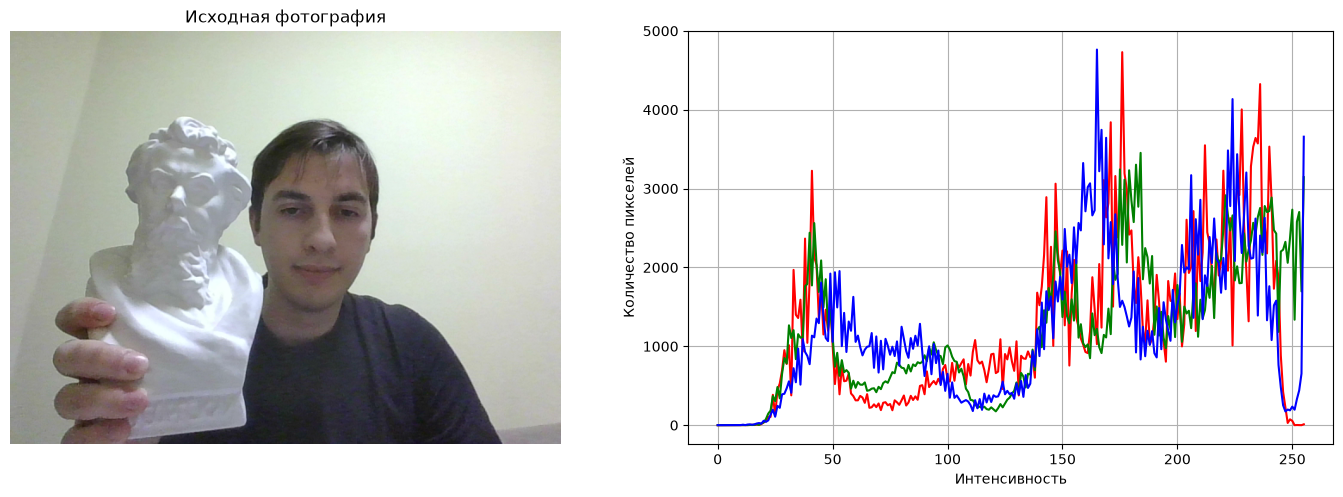

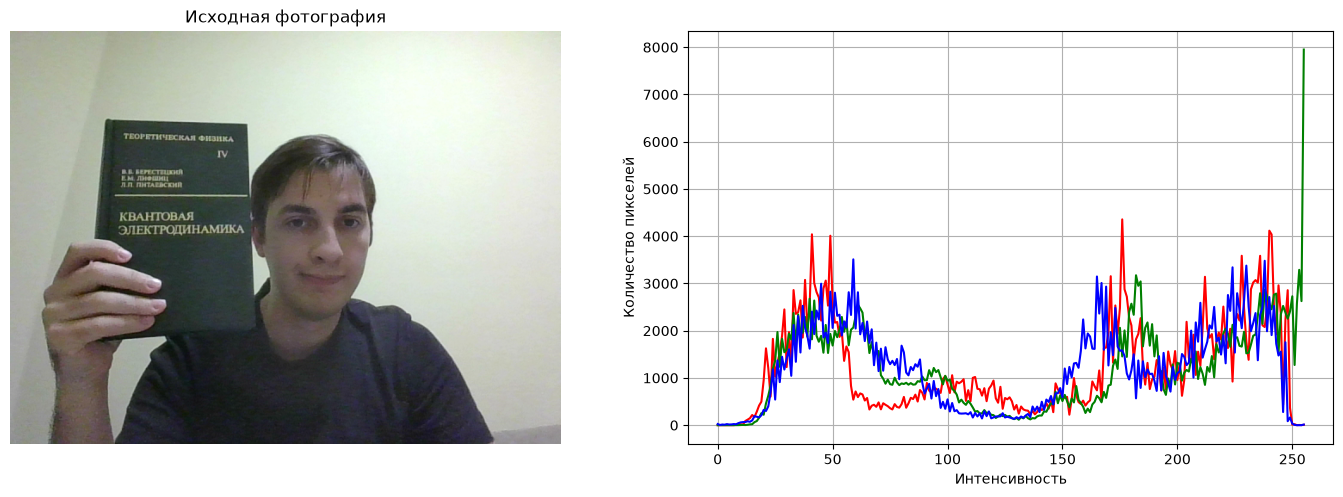

Переведите кадры с камеры в HSV. Постройте распределение там. Попробуйте наводить камеру на яркие объекты, посмотрите, что получается.

In [ ]:
cam = cv2.VideoCapture(0)
ret, frame = cam.read()
cam.release()

if ret:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(rgb)
    axes[0].axis("off")
    axes[0].set_title("Исходная фотография")

    channels = ["Цветовой тон (H)", "Насыщенность (S)", "Яркость (V)"]
    ranges = [180, 256, 256]
    colors = ["purple", "green", "orange"]
    for i in range(3):
        hist = cv2.calcHist([hsv], [i], None, [ranges[i]], [0, ranges[i]])

        axes[1 + i].plot(hist, color=colors[i])

        axes[1 + i].set_title(channels[i])
        axes[1 + i].set_xlabel("Значение канала")
        axes[1 + i].set_ylabel("Количество пикселей")

        axes[1 + i].set_xlim(0, ranges[i] - 1)
        axes[1 + i].grid(True)

    plt.tight_layout()
    plt.show()

**Результаты:**

---

На первой фотографии для цветового тона наблюдаем основные пики при H = {35, 50, 125}. Так как бОльшую часть фото занимает стена, которая отдает жёлтым цветом, мы видим большой пик при H = 35 и H = 50. Пик в районе H = 125 отдаёт одежда.

Насыщенность же в основном сосредоточена около нуля, так как стена почти белая и имеет низкую насыщенность.

У яркости есть три основных области: V = [40, 60] может соответствовать волосам и футболке; V = [180, 210] может соответстовать лицу и стене; а V = 255 соответствует пересвеченным частям стены.

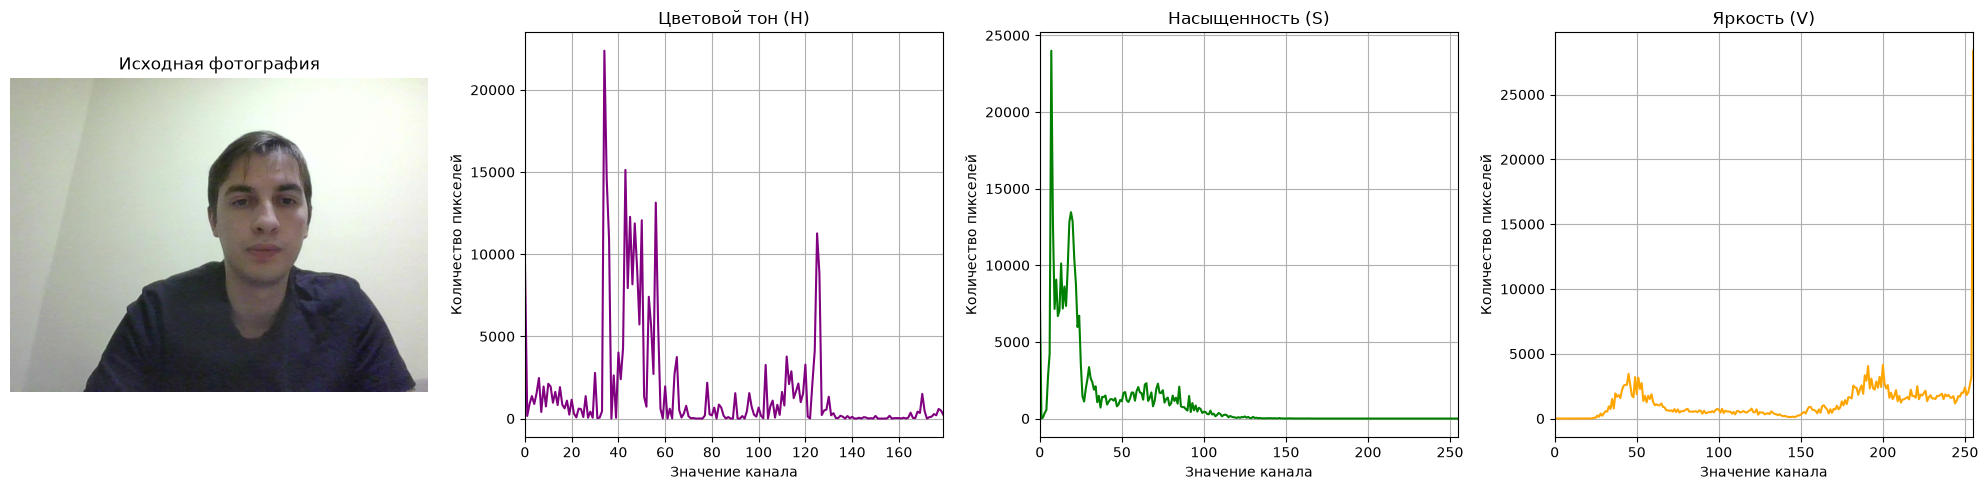

---

На второй фотографии для цветового тона наблюдаем главный пик при H = 120, который соответствует синему цвету ткани. По сравнению с первой фотографией этот пик значительно вырос, так как теперь бОльшую часть изображения занимает синяя ткань. При этом пики в районе H = 35 и H = 50 сохранились, поскольку на фотографии всё ещё присутствует светлая стена.

У насыщенности теперь наблюдаем две основные области: S = [0, 30] соответствует стене и другим не сильно насыщенным участкам изображения, а новый пик в районе S = 160 соответствует синей ткани, так как она достаточно насыщенна.

У яркости наблюдаем более равномерное распределение в диапазоне V = [50, 160], что может соответствовать синей ткани. Аналогично первой фотографии пики в районе V = [180, 200] могут соответствовать лицу и светлым участкам изображения, а V = 255 соответствует пересвеченным частям стены.

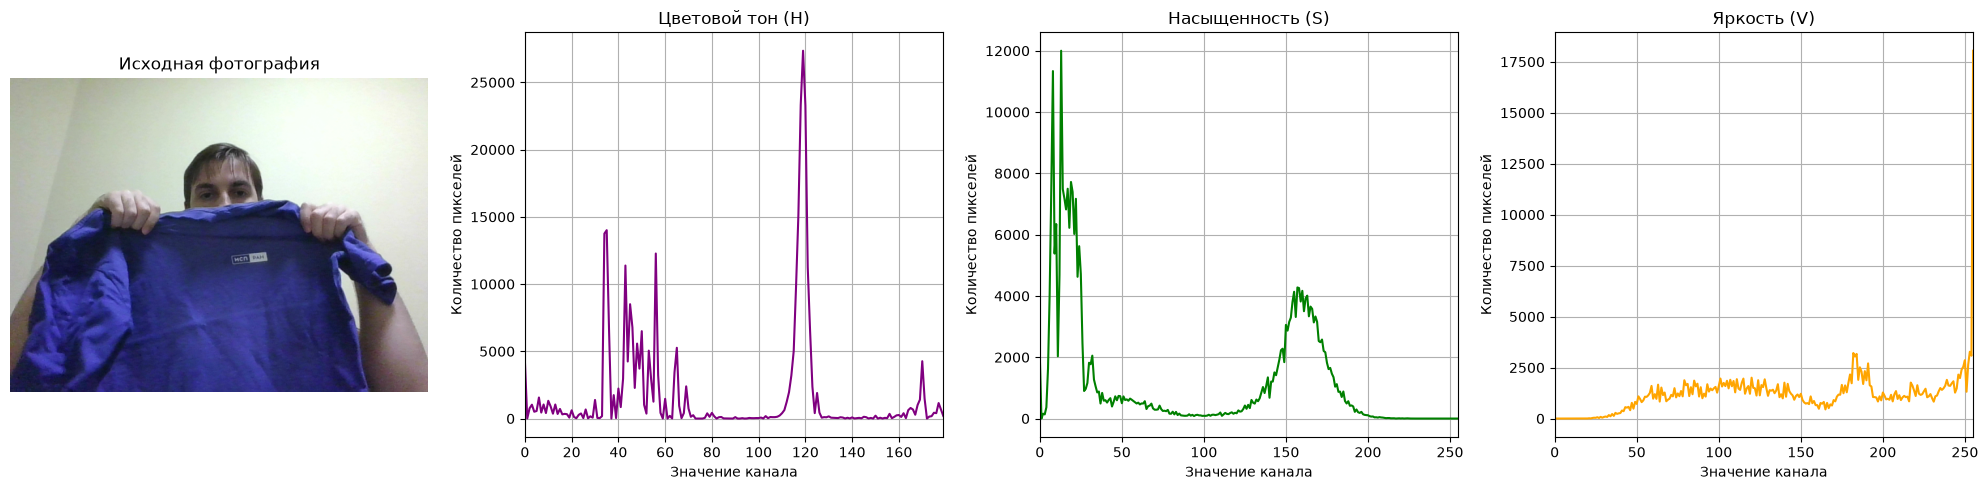

---

На третьей фотографии для цветового тона наблюдаем главный пик при H = 35, а также несколько меньших пиков в диапазоне H = [40, 130].

Насыщенность теперь почти полностью сосредоточена в диапазоне S = [0, 35], так как бОльшую часть изображения занимают белая статуэтка и светлая стена, которые имеют низкую насыщенность. По сравнению со второй фотографией пик при S = 160 полностью исчез, поскольку на изображении больше нет синей ткани.

У яркости основное распределение находится в диапазоне V = [110, 210], что может соответствовать статуэтке и её теням. Пик в районе V = 150 может быть связан с менее освещёнными частями статуэтки, а значения V = [180, 210] с более светлыми участками статуэтки и стены. Как и на предыдущих фотографиях, V = 255 соответствует пересвеченным частям изображения.

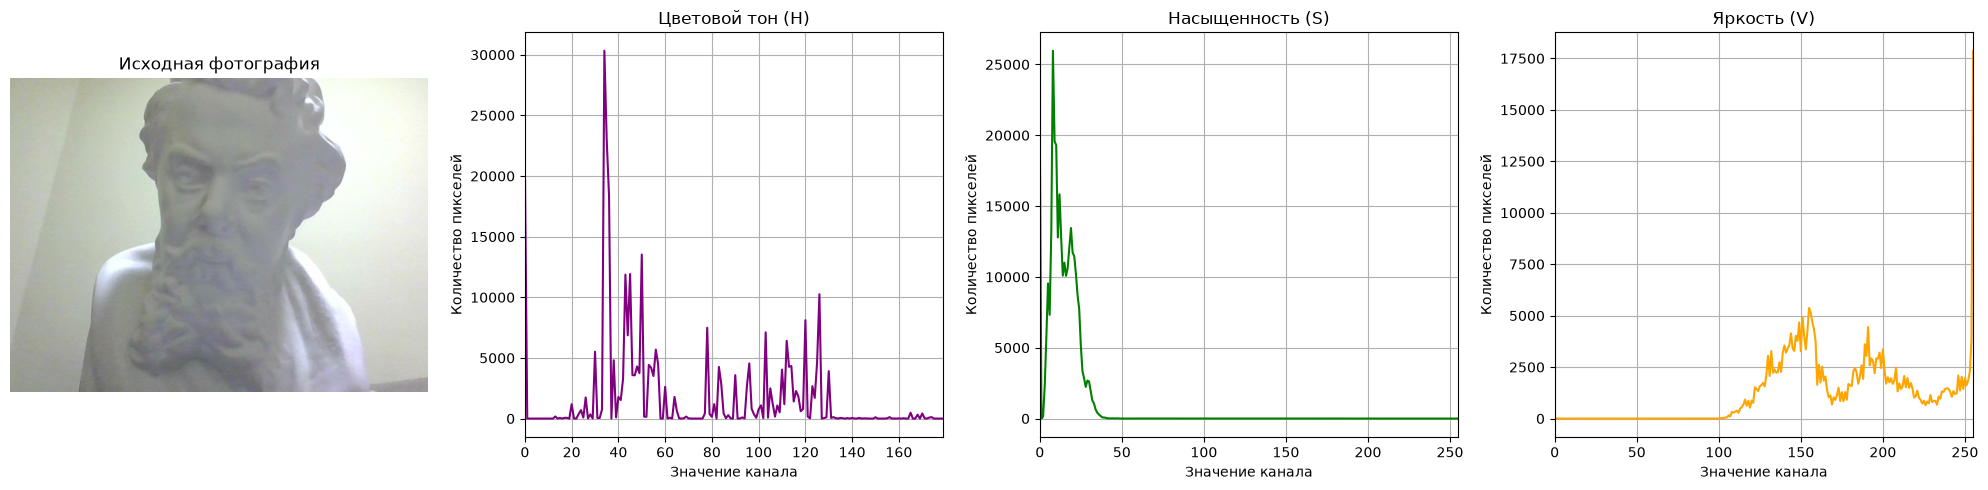

---

Прибавьте значение, регулируемое трекбаром, к каналам H, S, V (по очереди), а после этого добавьте перевод обратно в RGB и отображение на экран. Опишите, что получается. Запишите короткое видео и загрузите его вместе с домашкой.

In [ ]:
cam = cv2.VideoCapture(0)
cv2.namedWindow("mask")

cv2.createTrackbar("H", "mask", 0, 179, lambda x: None)
cv2.createTrackbar("S", "mask", 0, 255, lambda x: None)
cv2.createTrackbar("V", "mask", 0, 255, lambda x: None)

width = int(cam.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cam.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
video = cv2.VideoWriter("hsv_experiment.mp4", fourcc, 20.0, (width * 2, height))

while True:
    ret, frame = cam.read()

    if not ret:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    h_shift = cv2.getTrackbarPos("H", "mask")
    s_shift = cv2.getTrackbarPos("S", "mask")
    v_shift = cv2.getTrackbarPos("V", "mask")

    hsv[:, :, 0] = (hsv[:, :, 0].astype(np.int16) + h_shift) % 180

    hsv[:, :, 1] = np.clip(hsv[:, :, 1].astype(np.int16) + s_shift, 0, 255).astype(
        np.uint8
    )

    hsv[:, :, 2] = np.clip(hsv[:, :, 2].astype(np.int16) + v_shift, 0, 255).astype(
        np.uint8
    )

    result = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    original = frame.copy()
    modified = result.copy()

    cv2.putText(
        original,
        "Frame",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 255, 255),
        2,
    )

    cv2.putText(
        modified,
        f"H: +{h_shift}  S: +{s_shift}  V: +{v_shift}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2,
    )

    combined = np.hstack((original, modified))
    cv2.imshow("task3", combined)
    video.write(combined)

    if cv2.waitKey(30) & 0xFF == ord("q"):
        break

cam.release()
video.release()
cv2.destroyAllWindows()

**Результат (images/hsv_experiment.mp4)**:

1. 1-7 секунды видео: я поставил H = 104. Учитывая, что ранее кожа была красновата, что соответствует H = [10, 20], то логично, почему она по итогу стала синей. Потому что H = (15 + 104) mod 180 = 119, что соответствует синему цвету. Футболка сначала было синевато-чёрной, а после стала зеленоватой, потому что H = (120 + 104) mod 180 = 44, что соответствует зелёному цвету.

2. 8-14 секунды видео: я покрутил S от нуля до S = 200. Можно посмотреть на стену, которая была совсем ненасыщенной (S ~ 0), а после увеличения S стала очень насыщенной. 

3. Далее я повышаю до максимального значения V, наблюдаю вполне ожидаемый результат обычного увеличения яркости изображения.

### Задача 4

Реализуйте детектирование всех 8 объектов на изображении *objects.jpg* из репозитория.

Для каждого объекта должен быть набор операций, после которых остается только bounding box этого объекта. Постарайтесь не делать подгонов в духе "У объекта площадь ровно 749 пикселей". Ручка например длинная и тонкая, мячик круглый. Лучше ориентироваться на такие характеристики.

Бонусный вопрос - что интересного (или подозрительного?) вы можете сказать про это изображение?

**Исследование задачи:**

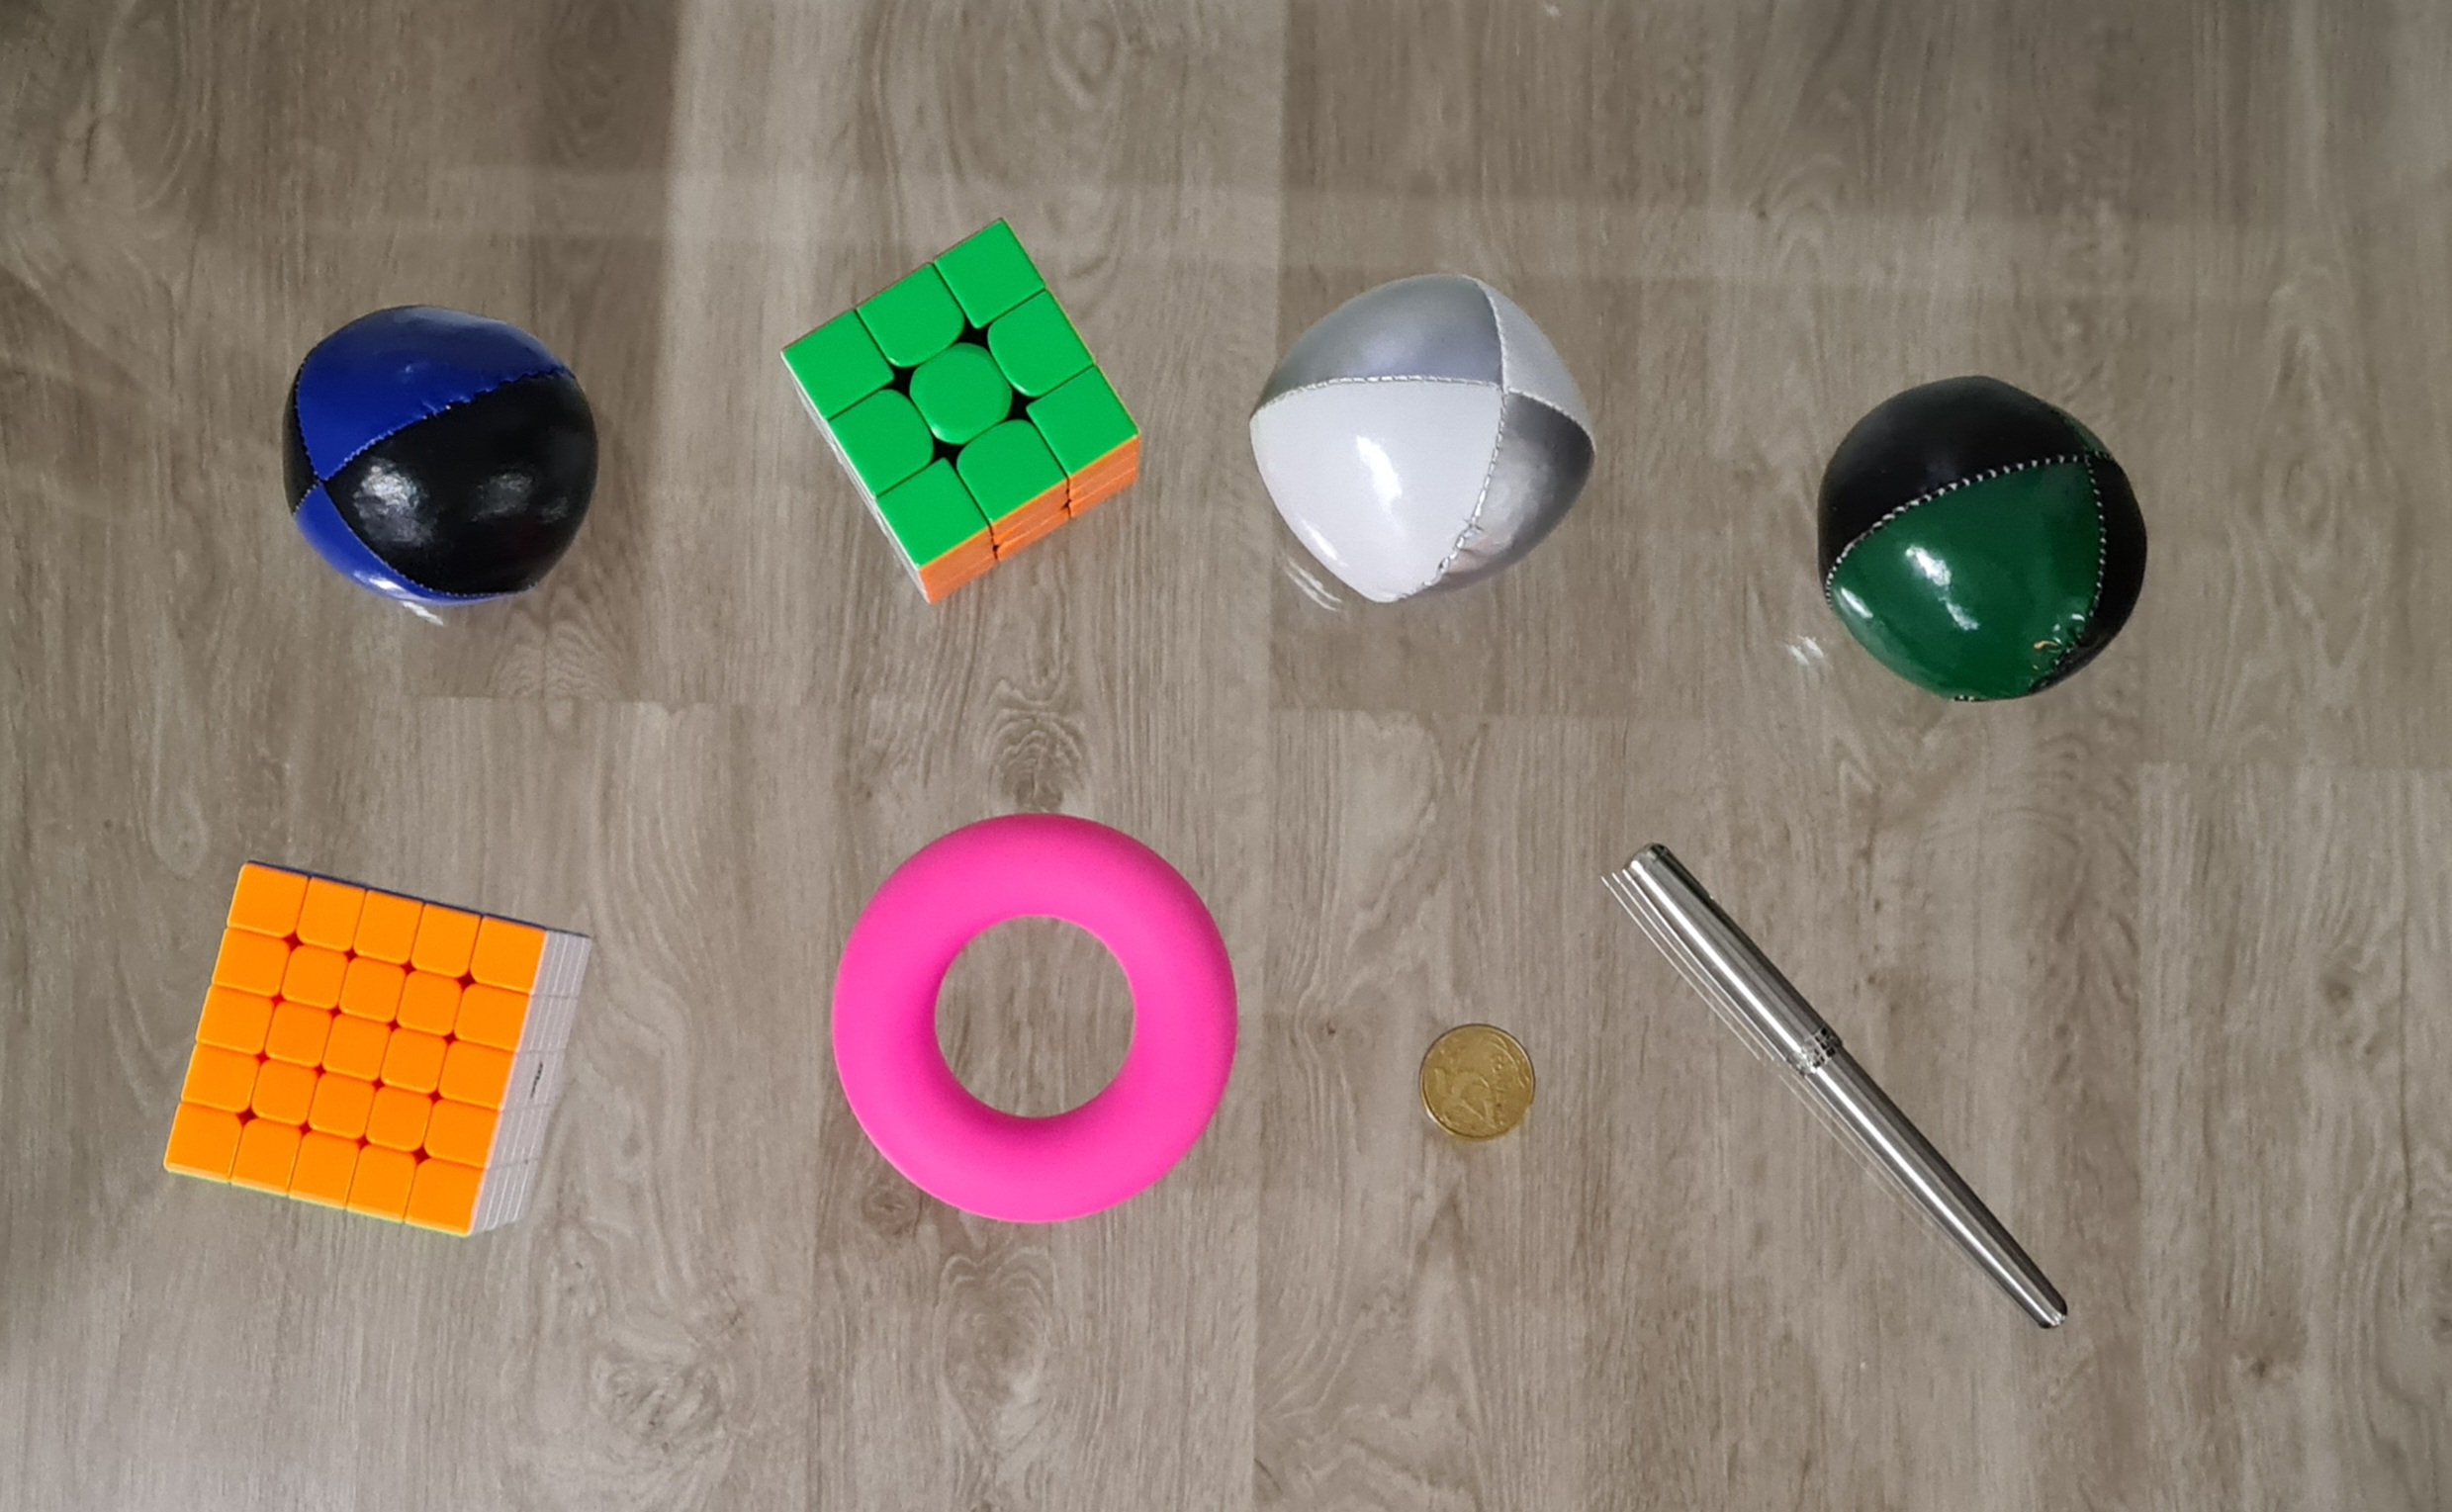

В первую очередь необходимо проанализировать изображение и оценить, какие подходы были бы уместны для детектирования каждого объекта.

| № | Объект | Цвет | Особенности |
|---|---|---|---|
| 1 | Сине-чёрный мяч | Синий и чёрный | Круглый |
| 2 | Кубик Рубика 3×3 | Зелёный и оранжевый | Почти квадратный |
| 3 | Бело-серый мяч | Белый и серый | Круглый |
| 4 | Зелёно-чёрный мяч | Зелёный и чёрный | Круглый |
| 5 | Кубик Рубика 5×5 | Оранжевый и белый | Почти квадратный |
| 6 | Эспандер | Розовый | Кольцеобразный |
| 7 | Монета | Золотистый | Круглый и меньше других |
| 8 | Ручка | Серебристый | Длинная и тонкая |

Уже исходя из таблицы очевидно, например, что часть предметов можно отсеить по форме, цвету. Также часть предметов можно отсеить по геометрическим характеристикам, которые характерны для определённого предмета, например:
  1. для ручки можно сказать, что отношение длины к ширине значительно больше 1;
  2. для мяча и монеты такое отношение будет примерно равно единице;
  3. монета, в свою очередь, относительно других предметов занимает заведомо меньшую площадь;
  4. с одной стороны у эспандера есть отверстие внутри, но с другой стороны это и не нужно, потому что он единственный розовый.

В конце концов, для некоторых предметов может понадобиться комбинация этих характеристик.

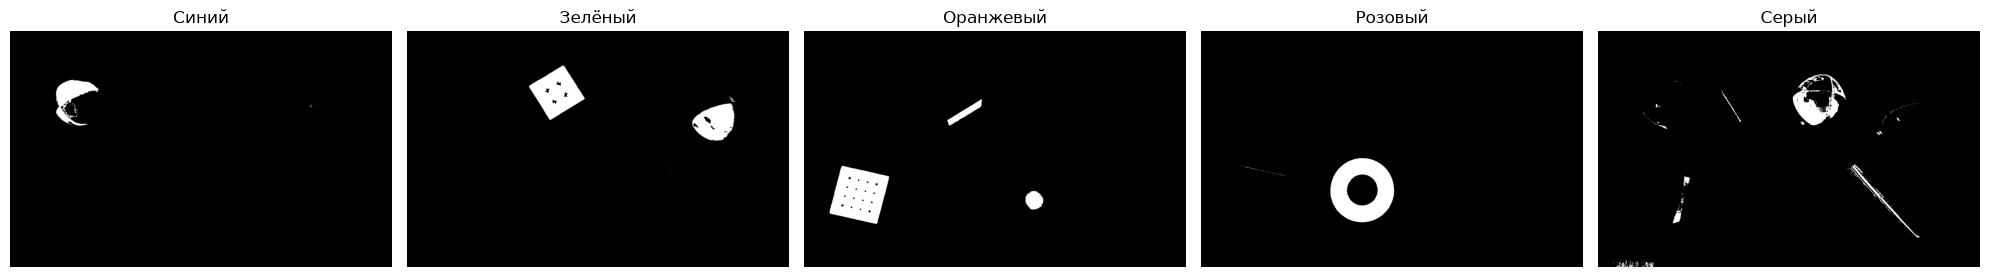

In [ ]:
frame = cv2.imread("./images/objects.jpg")
rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

# Диапазоны цветов в HSV
color_ranges = {
    "Синий": (np.array([100, 70, 30]), np.array([135, 255, 255])),
    "Зелёный": (np.array([35, 60, 30]), np.array([85, 255, 255])),
    "Оранжевый": (np.array([5, 100, 80]), np.array([25, 255, 255])),
    "Розовый": (np.array([140, 70, 50]), np.array([175, 255, 255])),
    "Серый": (np.array([0, 0, 120]), np.array([179, 15, 255])),
}

masks = {}
for name, (lower, upper) in color_ranges.items():
    masks[name] = cv2.inRange(hsv, lower, upper)

fig, axes = plt.subplots(1, 5, figsize=(20, 8))
for i, name in enumerate(color_ranges.keys()):
    axes[i].imshow(masks[name], cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"{name}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

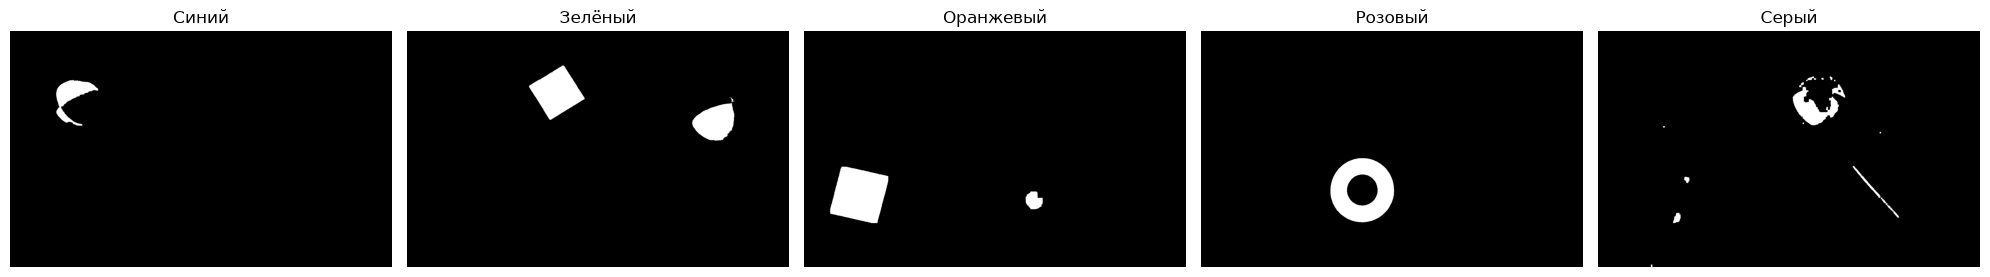

In [ ]:
# Параметры для открытия и закрытия
morphology_params = {
    "Синий": {"open": 10, "close": 7},
    "Зелёный": {"open": 3, "close": 21},
    "Оранжевый": {"open": 31, "close": 11},
    "Розовый": {"open": 5, "close": 3},
    "Серый": {"open": 9, "close": 11},
}

clean_masks = {}
for name, mask in masks.items():
    open_size = morphology_params[name]["open"]
    close_size = morphology_params[name]["close"]

    open_kernel = np.ones((open_size, open_size), np.uint8)
    close_kernel = np.ones((close_size, close_size), np.uint8)
    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, open_kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, close_kernel)
    clean_masks[name] = closed

fig, axes = plt.subplots(1, 5, figsize=(20, 8))
for i, name in enumerate(color_ranges.keys()):
    axes[i].imshow(clean_masks[name], cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"{name}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

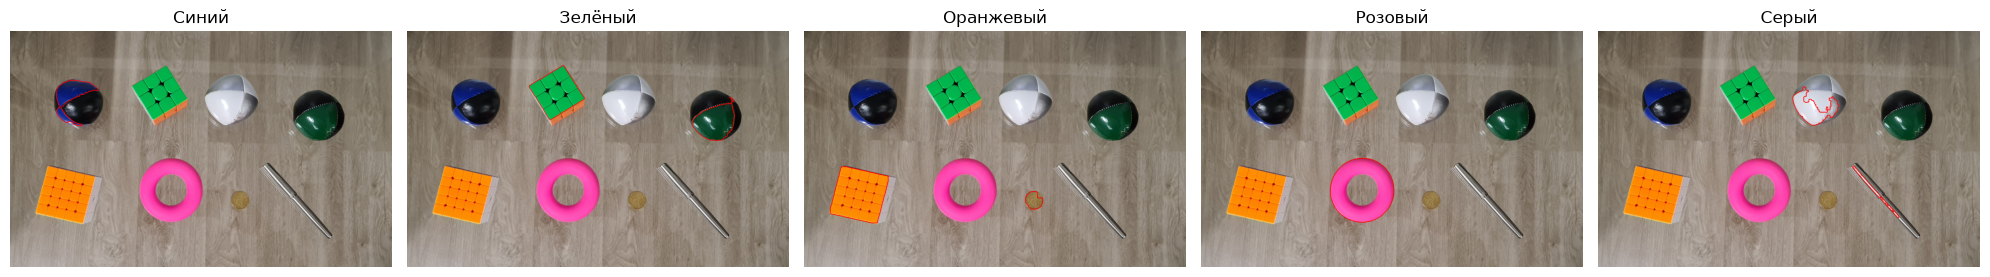

In [ ]:
contours_by_color = {}

image_area = rgb.shape[0] * rgb.shape[1]
min_relative_area = 0.001  # Так я удаляю контуры с маленькой площадью

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, (name, mask) in enumerate(clean_masks.items()):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    filtered_contours = []
    for contour in contours:
        area = cv2.contourArea(contour)
        relative_area = area / image_area
        if relative_area >= min_relative_area:
            filtered_contours.append(contour)

    contours_by_color[name] = filtered_contours
    result = rgb.copy()

    cv2.drawContours(result, filtered_contours, -1, (255, 0, 0), 3)

    axes[i].imshow(result)
    axes[i].set_title(f"{name}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

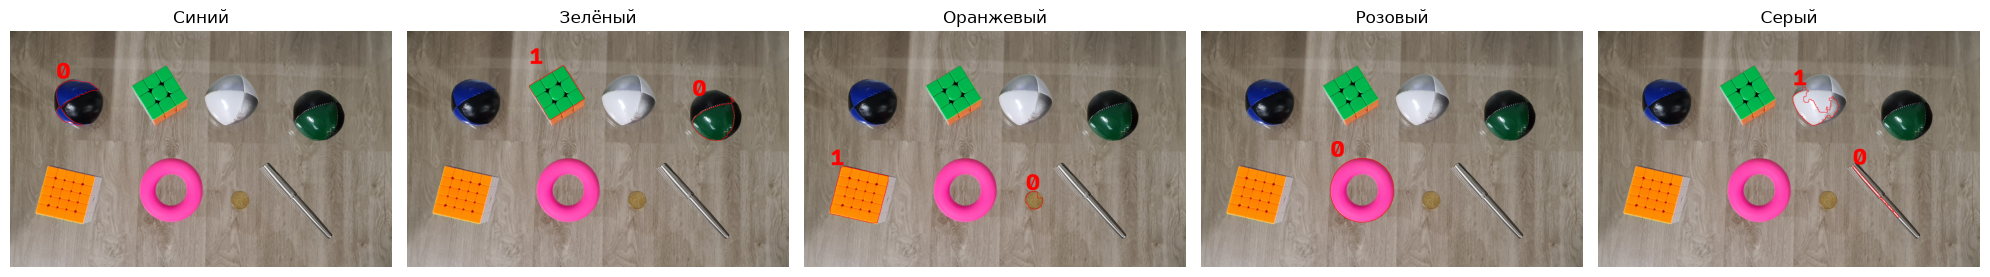

Геометрические характеристики объектов:

Цвет: Синий        | ID: 0 | Area: 30495.0 | Circularity: 0.24 | Elongation: 1.22 | Corners: 7
Цвет: Зелёный      | ID: 0 | Area: 47432.0 | Circularity: 0.57 | Elongation: 1.41 | Corners: 9
Цвет: Зелёный      | ID: 1 | Area: 68786.5 | Circularity: 0.70 | Elongation: 1.02 | Corners: 4
Цвет: Оранжевый    | ID: 0 | Area: 9282.0 | Circularity: 0.71 | Elongation: 1.05 | Corners: 9
Цвет: Оранжевый    | ID: 1 | Area: 101086.0 | Circularity: 0.72 | Elongation: 1.01 | Corners: 4
Цвет: Розовый      | ID: 0 | Area: 134643.0 | Circularity: 0.89 | Elongation: 1.01 | Corners: 8
Цвет: Серый        | ID: 0 | Area: 4897.0 | Circularity: 0.05 | Elongation: 23.49 | Corners: 2
Цвет: Серый        | ID: 1 | Area: 31903.0 | Circularity: 0.22 | Elongation: 1.15 | Corners: 10


In [119]:
detected_objects = []
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, (color_name, contours) in enumerate(contours_by_color.items()):
    result = rgb.copy()

    for j, contour in enumerate(contours):
        area = cv2.contourArea(contour)
        relative_area = area / image_area
        perimeter = cv2.arcLength(contour, True)

        # Считаю округлость
        if perimeter > 0:
            circularity = 4 * np.pi * area / (perimeter**2)
        else:
            circularity = 0

        # Нахожу минимальный повёрнутый прямоугольник вокруг контура
        rect = cv2.minAreaRect(contour)
        (_, _), (rw, rh), _ = rect

        # Считаю вытянутость
        if min(rw, rh) > 0:
            elongation = max(rw, rh) / min(rw, rh)
        else:
            elongation = 0

        # Аппроксимирую контур многоугольником
        approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)
        corners = len(approx)

        x, y, w, h = cv2.boundingRect(contour)

        detected_objects.append(
            {
                "color": color_name,
                "id": j,
                "contour": contour,
                "bbox": (x, y, w, h),
                "area": area,
                "relative_area": relative_area,
                "circularity": circularity,
                "elongation": elongation,
                "corners": corners,
            }
        )

        cv2.drawContours(result, [contour], -1, (255, 0, 0), 2)

        cv2.putText(
            result,
            str(j),
            (x, max(y - 10, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            5,
            (255, 0, 0),
            10,
        )

    axes[i].imshow(result)
    axes[i].set_title(color_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


print("Геометрические характеристики объектов:\n")
for obj in detected_objects:
    print(
        f"Цвет: {obj['color']:12} | "
        f"ID: {obj['id']} | "
        f"Area: {obj['area']:.1f} | "
        f"Circularity: {obj['circularity']:.2f} | "
        f"Elongation: {obj['elongation']:.2f} | "
        f"Corners: {obj['corners']}"
    )

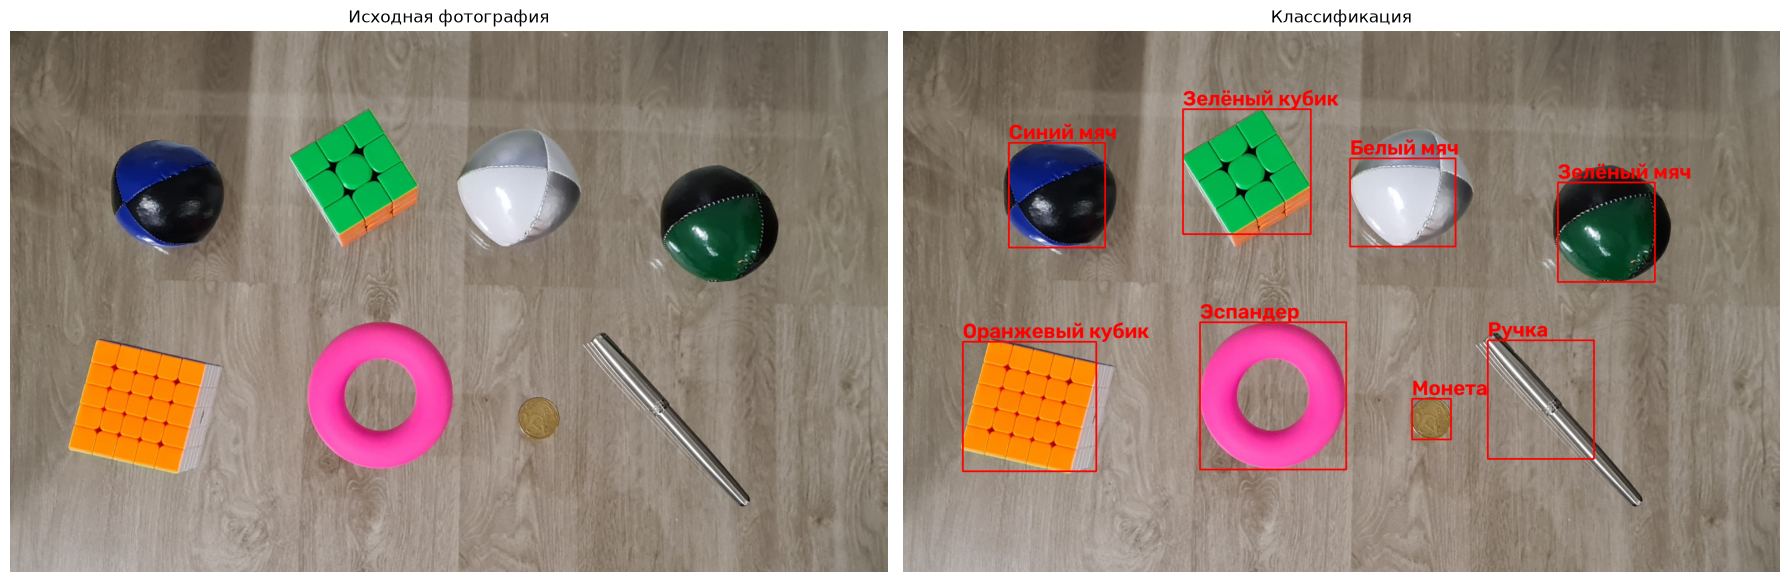

In [120]:
result = rgb.copy()

for obj in detected_objects:
    color = obj["color"]
    circularity = obj["circularity"]
    elongation = obj["elongation"]
    corners = obj["corners"]

    name = "Unknown"

    if color == "Синий":
        name = "Синий мяч"

    elif color == "Зелёный":
        if corners == 4 and elongation < 1.3:
            name = "Зелёный кубик"
        else:
            name = "Зелёный мяч"

    elif color == "Оранжевый":
        if corners == 4:
            name = "Оранжевый кубик"
        else:
            name = "Монета"

    elif color == "Розовый":
        name = "Эспандер"

    elif color == "Серый":
        if elongation > 5:
            name = "Ручка"
        else:
            name = "Белый мяч"

    obj["name"] = name

    x, y, w, h = obj["bbox"]

    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        3
    )

    cv2.putText(
        result,
        name,
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        2,
        (255, 0, 0),
        2
    )

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(rgb)
axes[0].set_title("Исходная фотография")
axes[0].axis("off")

axes[1].imshow(result)
axes[1].set_title("Классификация")
axes[1].axis("off")

plt.tight_layout()
plt.show()